# Coordination de satellites

### Etudiants :
- Jawher JRIBY 3702809
- Mélanie DELLUC 21104033

## 1 - Introduction

L'objectif de ce projet est d'étudier un problème d'allocation multi-agents de tâches dans lequel des tâches d’observations doivent être allouées à des constellations de satellites en orbite autour de la Terre.

...

## 2 - Préparation : Instances et planification des tâches

In [1]:
from typing import Callable
import random
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np

### 2.1 - Générateur aléatoire

Dans un premier temps, nous allons implémenter un générateur aléatoire d'instances du problème EOSCSP à partir d'un nombre de satellites, d'utilisateurs exclusifs et de tâches. Pour cela, nous devons établir les structures de données nécessaires à la représentation du problème (EOSCSP, satellites, utilisateurs, requêtes, observations, solutions) et leurs contraintes associées avant de générer des instances de chaque élément. 

Nous avons commencé par créer des instances aléatoires générales, donc sans se préoccuper de l'exclusivité. Puis, nous y avons ajouté les contraintes supplémentaires liées au problème d'exclusivité (section 2.1.5). 

#### 2.1.1 - Structures de données

In [2]:
class EOSCSP :
    def __init__(self, eoscsp_id : int, S : set['Satellite'], U : set['User'], R : set['Request'], O : set['Observation']):
        self.eoscsp_id = eoscsp_id
        self.S = S
        self.U = U 
        self.R = R
        self.O = O

In [3]:
class Satellite :
    def __init__(self, s_id : int, t_start: float, t_end: float, kappa: int, tau: int):
        self.s_id = s_id
        self.t_start = t_start
        self.t_end = t_end
        self.kappa = kappa
        self.tau = tau
        # A MODIFIER : tau: Callable[['Observation', 'Observation'], float]

In [4]:
class User :
    def __init__(self, u_id : int, e : set[tuple['Satellite', float, float]], p : int):
        self.u_id = u_id
        self.e = e
        self.p = p

In [5]:
class Request :
    def __init__(self, r_id : int, t_start : float, t_end : float, duration : float, reward : float, p : tuple[float, float, float], u : User, thetas : list['Observation']):
        self.r_id = r_id
        self.t_start = t_start
        self.t_end = t_end
        self.duration = duration
        self.reward = reward
        self.p = p
        self.u = u
        self.thetas = thetas

In [6]:
class Observation :
    def __init__(self, o_id : int, t_start : float, t_end : float, duration : float, r : 'Request', reward : float, s : 'Satellite', u : 'User', p : int):
        self.o_id = o_id
        self.t_start = t_start 
        self.t_end = t_end
        self.duration = duration
        self.r = r
        self.reward = reward
        self.s = s
        self.u = u
        self.p = p

In [96]:
class Solution :
    def __init__(self, sol_id : int, M : dict['Observation', float]):
        self.sol_id = sol_id
        self.M = M 

#### 2.1.2 - Contraintes sur les données

In [8]:
def constraints_EOSCSP():
    return

In [9]:
def constraints_satellites(s):
    errors = []

    if s.t_start >= s.t_end :
        errors.append("Sattelite s : invalid time -> start > end")

    if s.kappa < 1 :
        errors.append("Sattelite s : invalid capacity -> kappa < 1")

    #if s.tau is not Callable:
    #    errors.append("Sattelite s : transition function undefined")

    return errors

In [10]:
def constraints_users(u):
    errors = []

    if u.p < 1 :
        errors.append("User u : invalid priority -> p < 1")

    #for (s, i, j) in u.e :
    #    if s not in P.S :
    #        errors.append("User u : exclusive references unknown satellite")

        #else :
        #    if not (s.t_start <= i < j <= s.t_end) :
        #        errors.append("User u: exclusive window outside satellite horizon")

    
    # global no-overlap constraint
    #collect all exclusive windows by satellite
    #for each satellite s:
    #    for each pair of windows (a,b) and (c,d):
    #        if intervals overlap:
    #            errors.add("Overlapping exclusive windows on satellite s")
    
    return errors

In [11]:
def constraints_requests(r, users):
    errors = []

    if r.t_start >= r.t_end :
        errors.append("Request r : invalid time -> start > end")

    if r.duration <= 0 :
        errors.append("Request r : invalid duration -> duration <= 0")

    if r.reward < 0 :
        errors.append("Request r : invalid reward -> reward < 0")

    if r.u not in users :
        errors.append("Request r: requester does not exist")

    #for o in r.thetas :
    #    if o not in observations :
    #        errors.append("Request r : invalid thetas -> unknown obsevation")
                
    return errors

In [12]:
def constraints_observations(o, requests, satellites):
    errors = []

    if o.t_start >= o.t_end :
        errors.append("Observation o : invalid time -> start > end")

    if o.r not in requests:
        errors.append("Observation o : unknown request")

    if o.s not in satellites:
        errors.append("Observation o : unknown satellite")

    if o.u.u_id != o.r.u.u_id:
        errors.append("Observation o: owner mismatch with request")

    if o.duration != o.r.duration:
        errors.append("Observation o: duration must equal request duration")

    if not (o.s.t_start <= o.t_start < o.t_end <= o.s.t_end):
        errors.append("Observation o: outside satellite horizon")
            
    return errors

In [13]:
def constraints_solutions():
    return

#### 2.1.3 - Construction d'instances des données (hors exclusivité)

In [14]:
def generate_satellites(nb_satellites, horizon, kappa_min, kappa_max, tau=1, max_tries=10000):
    S = set()

    # à revoir plus tard la fonction de transition
    #def f_tau():
    #    return 1
    
    for i in range(nb_satellites) :
        for j in range(max_tries):
            start = 0
            end = start + horizon
            kappa = random.randint(kappa_min, kappa_max)
            s = Satellite(s_id=i, t_start=start,t_end=end,kappa=kappa,tau=tau,)
            if constraints_satellites(s) == [] :
                S.add(s)
                break
    return S

In [47]:
def generate_users(nb_users, min_priority=1, max_priority=10, max_tries=10000):
    U = set()

    for i in range(nb_users):
        for j in range(max_tries):
            p = random.randint(min_priority, max_priority)
            u = User(u_id=i, e=set(), p=p,)

            if constraints_users(u) == [] :
                U.add(u)
                break
    return U

In [48]:
def generate_requests(users, nb_requests_per_user, horizon, d_min, d_max, r_min, r_max, max_tries=10000):
    R = set()
    r_id = 0

    for u in users :
        for i in range(nb_requests_per_user) :
            for j in range(max_tries) :
                d = random.uniform(d_min, d_max)
                start = random.uniform(0.0, horizon - d)
                end = start + random.uniform(d, horizon - start)
                reward = random.uniform(r_min, r_max)
                p = 0 # A MODIFIER : pas encore bien compris ce que c'est 

                r = Request(r_id=r_id, t_start=start, t_end=end, duration=d, reward=reward, p=p, u=u, thetas=[],)

                if constraints_requests(r, users) == [] :
                    R.add(r)   
                    r_id += 1
                    break
    return R

In [49]:
def generate_observations(satellites, users, requests, opp_per_request, obs_window_min, obs_window_max, max_tries=10000):
    O = set()

    users_by_id = {u.u_id : u for u in users}

    o_id = 0
    for r in requests :
        for i in range(opp_per_request) :
            for j in range(max_tries) :
                s = random.choice(list(satellites))

                d = max(r.duration, random.uniform(obs_window_min, obs_window_max))
                start_min = r.t_start
                start_max = r.t_end - d
                if start_max < start_min :
                    continue

                o_start = random.uniform(start_min, start_max)
                o_end = o_start + d

                o = Observation(o_id=o_id, r=r, u=r.u, s=s, t_start=o_start, t_end=o_end, duration=r.duration, reward=r.reward, p=users_by_id[r.u.u_id].p,)

                if constraints_observations(o, requests, satellites) == []:
                    O.add(o)
                    r.thetas.append(o_id)
                    o_id += 1
                    break
    
    return O

In [50]:
def generate_EOSCSP(i, satellites, users, requests, observations):
    return EOSCSP(eoscsp_id=i, S=satellites, U=users, R=requests, O=observations)

#### 2.1.4 - Tests sur des instances sans exclusivité

In [126]:
def plot_eoscsp_windows(
    EOSCSP,
    plan=None,  # <-- NEW: list of (Observation, start, end)
    title="EOSCSP - Observation windows",
    show_labels=True,
    show_exclusives=True,
    show_plan_labels=True,
):
    """
    Plot:
      - Observation validity windows as transparent rectangles
      - Exclusive time windows as hatched rectangles
      - (Optional) A schedule/solution 'plan' as solid rectangles on top

    plan: list of tuples (obs, start, end) where obs is an Observation
    """

    satellites = EOSCSP.S
    observations = EOSCSP.O
    users = EOSCSP.U

    # --- Satellite order ---
    sat_ids = []
    for idx, s in enumerate(satellites):
        sid = getattr(s, "s_id", idx)
        sat_ids.append(sid)
    sat_ids_sorted = sorted(sat_ids)

    # --- User ids present (from observations + plan + optionally from users) ---
    user_ids = sorted({getattr(o.u, "u_id", 0) for o in observations})
    if plan is not None:
        user_ids = sorted(set(user_ids) | {getattr(obs.u, "u_id", 0) for obs in plan.M.keys()})
    if users is not None:
        user_ids = sorted({u.u_id for u in users} | set(user_ids))

    # --- Colors ---
    cmap = plt.get_cmap("tab10")
    user_color = {uid: cmap(i % 10) for i, uid in enumerate(user_ids)}

    fig, ax = plt.subplots(figsize=(12, 7))
    row_height = 0.8
    y_gap = 0.35

    # --- Time bounds: include observations, exclusives and plan ---
    all_starts = [o.t_start for o in observations]
    all_ends = [o.t_end for o in observations]

    if show_exclusives and users is not None:
        for u in users:
            for ew in getattr(u, "e_u", []):
                all_starts.append(ew.t_start)
                all_ends.append(ew.t_end)

    if plan is not None:
        for obs in plan.M.keys():
            all_starts.append(obs.t_start)
            all_ends.append(obs.t_end)

    t_min = min(all_starts) if all_starts else 0.0
    t_max = max(all_ends) if all_ends else 1.0

    # Helpers
    def y_of_sat_id(sid):
        return sat_ids_sorted.index(sid) * (row_height + y_gap)

    def sid_of_sat(s_obj):
        return getattr(s_obj, "s_id", None)

    # -------------------------
    # 1) Draw exclusive windows (background, hatched)
    # -------------------------
    if show_exclusives and users is not None:
        for u in users:
            uid = getattr(u, "u_id", 0)
            for ew in getattr(u, "e_u", []):

                sid = sid_of_sat(ew.s)
                if sid is None or sid not in sat_ids_sorted:
                    continue

                y = y_of_sat_id(sid)
                x = ew.t_start
                w = ew.t_end - ew.t_start
                if w <= 0:
                    continue

                hatched = Rectangle(
                    (x, y),
                    w,
                    row_height,
                    facecolor=user_color.get(uid, cmap(0)),
                    edgecolor=user_color.get(uid, cmap(0)),
                    linewidth=1.0,
                    alpha=0.18,
                    hatch="///",
                    zorder=0,
                )
                ax.add_patch(hatched)

    # -------------------------
    # 2) Draw observation windows (transparent)
    # -------------------------
    for o in observations:
        uid = getattr(o.u, "u_id", 0)
        sid = sid_of_sat(o.s)
        if sid is None or sid not in sat_ids_sorted:
            continue

        y = y_of_sat_id(sid)
        x = o.t_start
        w = o.t_end - o.t_start
        if w <= 0:
            continue

        rect = Rectangle(
            (x, y),
            w,
            row_height,
            facecolor=user_color.get(uid, cmap(0)),
            edgecolor="black",
            linewidth=1,
            alpha=0.25,
            zorder=2,
        )
        ax.add_patch(rect)

        if show_labels:
            oid = getattr(o, "o_id", None)
            rid = getattr(getattr(o, "r", None), "r_id", None)
            label = f"o{oid},r{rid}" if oid is not None else "obs"
            ax.text(
                x + w / 2,
                y + row_height / 2,
                label,
                ha="center",
                va="center",
                fontsize=8,
                alpha=0.9,
                zorder=3,
            )

    # -------------------------
    # 3) Draw plan (solid rectangles on top)
    # -------------------------
    if plan is not None:
        for obs in plan.M.keys():
            start = obs.t_start
            end = obs.t_end
            
            uid = getattr(obs.u, "u_id", 0)
            sid = sid_of_sat(obs.s)
            if sid is None or sid not in sat_ids_sorted:
                continue

            y = y_of_sat_id(sid)

            w = end - start
            if w <= 0:
                continue

            # Solid execution block (slightly shorter height so it looks "inside" the window)
            pad = 0.08
            exec_rect = Rectangle(
                (start, y + pad),
                w,
                row_height - 2 * pad,
                facecolor=user_color.get(uid, cmap(0)),
                edgecolor="black",
                linewidth=2.0,
                alpha=0.85,
                zorder=5,
            )
            ax.add_patch(exec_rect)

            if show_plan_labels:
                oid = getattr(obs, "o_id", None)
                label = f"o{oid}" if oid is not None else "exec"
                ax.text(
                    start + w / 2,
                    y + row_height / 2,
                    label,
                    ha="center",
                    va="center",
                    fontsize=9,
                    alpha=0.95,
                    zorder=6,
                )

    # --- Y axis labels ---
    y_ticks = []
    y_labels = []
    for sid in sat_ids_sorted:
        y_ticks.append(y_of_sat_id(sid) + row_height / 2)
        y_labels.append(f"S{sid}")
    ax.set_yticks(y_ticks)
    ax.set_yticklabels(y_labels)

    # --- X axis ---
    ax.set_xlim(t_min - 0.5, t_max + 0.5)
    ax.set_xlabel("time")
    ax.set_ylabel("satellite")
    ax.set_title(title)

    # --- Legend (users) ---
    handles = []
    labels = []
    for uid in user_ids:
        patch = Rectangle((0, 0), 1, 1, facecolor=user_color[uid], edgecolor="black", alpha=0.25)
        handles.append(patch)
        labels.append(f"u{uid}")
    ax.legend(handles, labels, loc="upper right")

    ax.grid(True, axis="x", linestyle="--", alpha=0.4)
    plt.tight_layout()
    plt.show()


In [127]:
horizon = 3000.0

satellites = generate_satellites(3, horizon, 100, 200)
users = generate_users(3)
requests = generate_requests(users, 2, horizon, 5.0, 15.0, 1.0, 50.0)
observations = generate_observations(satellites, users, requests, 3, 30.0, 120.0)

eoscsp_1 = generate_EOSCSP(0, satellites, users, requests, observations)

print(f"Generated: |S|={len(satellites)} |U|={len(users)} |R|={len(requests)} |O|={len(observations)}")

Generated: |S|=3 |U|=3 |R|=6 |O|=18


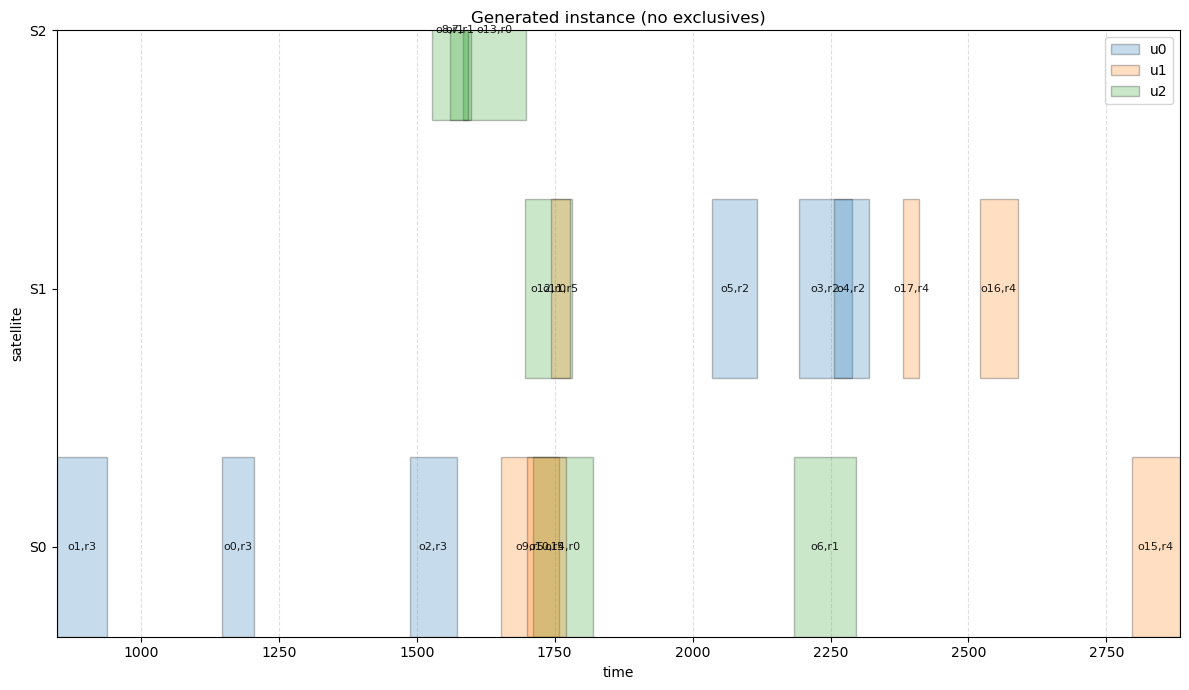

In [128]:
plot_eoscsp_windows(eoscsp_1, title="Generated instance (no exclusives)")

#### 2.1.5 - Ajout de l'exclusivité

Rappel des modifications :
- User : e n'est plus à None, chaque fenêtre exclusive contient un satellite et un intervalle de temps
- Observation : si o est dans fenêtre exclusive alors o.u doit être propriétaire de cette exclusivité - si o appratient à u0 alors elle peut être dans une exclusivité ou hors de toutes les exclusivités 
- Contraintes globales : 1 - deux users différents ne peuvent pas utiliser la même exclusivité 2 - une observation non prioritaire ne peut pas intersecter une exclusivité
- Visualisation : zones hachurées du plot

In [129]:
def overlap(a_start, a_end, b_start, b_end):
    return not (a_end <= b_start or b_end <= a_start)


def constraints_exclusifs_users(u, satellites, users_exclusifs):
    errors = []

    for (s, start, end) in u.e :
        if s not in satellites :
            errors.append("User u : exclusive references unknown satellite")
        else :
            if not (s.t_start <= start < end <= s.t_end) :
                errors.append("User u: exclusive window outside satellite horizon")

    for ue in users_exclusifs:
        for (s,start,end) in ue.e :
            if s in u.e :
                if overlap(u.e.t_start, u.e.t_end, start, end):
                    errors.append("Overlapping exclusive windows on satellite s")

    return errors

In [130]:
def constraints_exclusifs_observations(o, users):
    errors = []

    for u in users :
        if u.e == None :
            continue
        else :
            for (s,start,end) in u.e :
                if o.s.s_id == s.s_id and overlap(o.t_start, o.t_end, start, end):
                    if o.u.u_id != u.u_id :
                        errors.append("Observation o : Non-priority observation -> exclusive zone")
                        
    return errors

In [131]:
def generate_users_exclusifs(k, satellites, nb_users, min_priority=1, max_priority=10, e_dur_min=50, e_dur_max=250, max_tries=10000):
    U = set()

    for i in range(nb_users):
        for j in range(max_tries):
            p = random.randint(min_priority, max_priority)

            s = random.choice(list(satellites))
            dur = random.uniform(e_dur_min, e_dur_max)
            horizon = s.t_end - s.t_start
            if dur >= horizon:
                dur = max(1.0, 0.5 * horizon)
            start = random.uniform(s.t_start, s.t_end - dur)
            end = start + dur
            res = set()
            res.add((s,start,end))
            u = User(u_id=i+k, e=res, p=p,) # pour l'instant on suppose qu'il y a qu'une seule fenêtre exclusive par user

            if constraints_users(u) == [] and constraints_exclusifs_users(u, satellites, U) == [] :
                U.add(u)
                break
    return U


def generate_observations(satellites, users, requests, opp_per_request, obs_window_min, obs_window_max, max_tries=10000):
    O = set()

    users_by_id = {u.u_id : u for u in users}

    o_id = 0
    for r in requests :
        for i in range(opp_per_request) :
            for j in range(max_tries) :
                s = random.choice(list(satellites))

                d = max(r.duration, random.uniform(obs_window_min, obs_window_max))
                start_min = r.t_start
                start_max = r.t_end - d
                if start_max < start_min :
                    continue

                o_start = random.uniform(start_min, start_max)
                o_end = o_start + d

                o = Observation(o_id=o_id, r=r, u=r.u, s=s, t_start=o_start, t_end=o_end, duration=r.duration, reward=r.reward, p=users_by_id[r.u.u_id].p,)

                if constraints_observations(o, requests, satellites) == [] and constraints_exclusifs_observations(o, users) == [] :
                    O.add(o)
                    r.thetas.append(o_id)
                    o_id += 1
                    break
    
    return O

In [147]:
horizon = 3000.0

satellites = generate_satellites(3, horizon, 100, 200)
users_no_exclusifs = generate_users(1)
users_exclusifs = generate_users_exclusifs(len(users_no_exclusifs), satellites, 2)
users = users_no_exclusifs.union(users_exclusifs)
requests = generate_requests(users, 2, horizon, 5.0, 15.0, 1.0, 50.0)
observations = generate_observations(satellites, users, requests, 3, 30.0, 120.0)

eoscsp_2 = generate_EOSCSP(1, satellites, users, requests, observations)

print(f"Generated: |S|={len(satellites)} |U|={len(users)} |R|={len(requests)} |O|={len(observations)}")

Generated: |S|=3 |U|=3 |R|=6 |O|=15


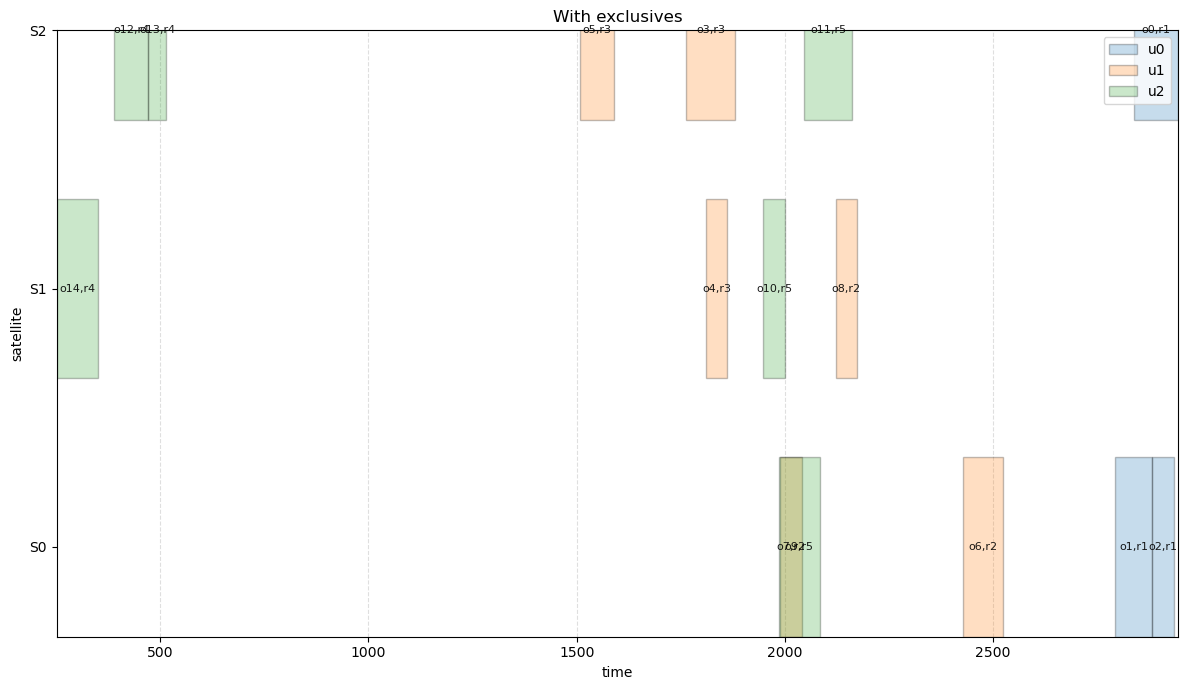

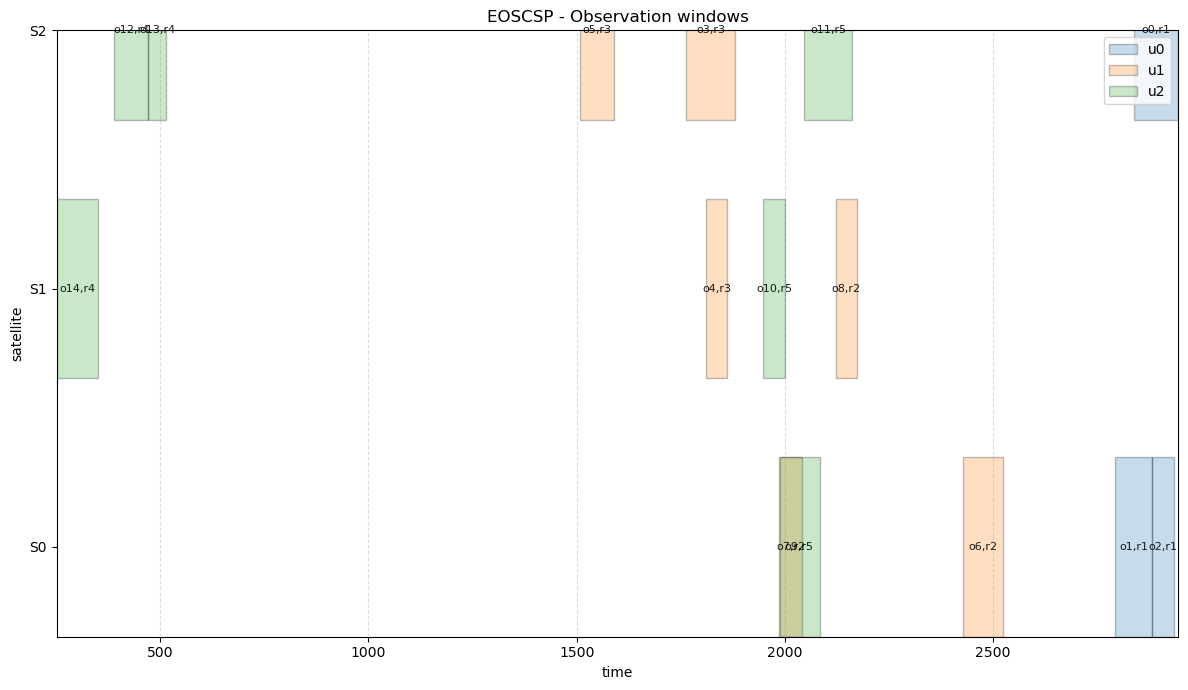

In [148]:
plot_eoscsp_windows(eoscsp_2, title="With exclusives", show_exclusives=True)
plot_eoscsp_windows(eoscsp_2, show_exclusives=False)

In [134]:
# rajouter la contrainte dans generate observations
# rajouter les zones hachurées dans le graphique

### 2.2 - Méthode de planification

Dans un second temps, nous allons concevoir une méthode de planification permettant à un utilisateur de planifier l’exécution d’un ensemble de tâches sur un satellite en tenant compte des contraintes temporelles sur ces tâches.

Dans le but de trouver une solution optimale du plan calculé, mais en limitant tout de même le temps de calcul nécessaire à cette génération, nous comptons implémenter une heuristique gloutonne.

DETAILLER PLUS TARD L'HEURISTIQUE SELON LE CHOIX D'IMPLEMENTATION


RAJOUTER NOTION DE PRIORITE OBSERVATION

In [135]:
def gaps(plan, t_min, t_max):
    """
    plan: list of (task, start, end) sorted by start
    returns list of (gap_start, gap_end, prev_item, next_item)
      where prev_item/next_item are (task,start,end) or None
    """
    if not plan:
        return [(t_min, t_max, None, None)]

    plan = sorted(plan, key=lambda x: x[1])
    res = []

    # before first
    first = plan[0]
    if t_min < first[1]:
        res.append((t_min, first[1], None, first))

    # between
    for i in range(len(plan) - 1):
        prev_item = plan[i]
        next_item = plan[i + 1]
        if prev_item[2] < next_item[1]:
            res.append((prev_item[2], next_item[1], prev_item, next_item))

    # after last
    last = plan[-1]
    if last[2] < t_max:
        res.append((last[2], t_max, last, None))

    return res

In [136]:
def generate_solution(tasks, lam=0.1, eps=1e-6, tau=None, sol_id=0):
    if not tasks:
        return Solution(sol_id, {}), 0.0

    if tau is None:
        tau = lambda a, b: 0.0

    sat = tasks[0].s
    t_min = sat.t_start
    t_max = sat.t_end

    def score(t):
        slack = t.t_end - t.t_start
        return (t.reward / t.duration) + lam * (1.0 / max(slack, eps))

    tasks_sorted = sorted(tasks, key=lambda t: (-score(t), t.t_end))

    plan = []
    tot_reward = 0.0

    for t in tasks_sorted:
        best_start = None
        candidate_gaps = gaps(plan, t_min=t_min, t_max=t_max)

        for (g_start, g_end, g_prev, g_next) in candidate_gaps:
            start = max(t.t_start, g_start)

            if g_prev is not None:
                prev_task, prev_start, prev_end = g_prev
                start = max(start, prev_end + tau(prev_task, t))

            end = start + t.duration

            if end <= t.t_end and end <= g_end:
                if g_next is not None:
                    next_task, next_start, next_end = g_next
                    if end + tau(t, next_task) > next_start:
                        continue

                best_start = start
                break

        if best_start is not None:
            plan.append((t, best_start, best_start + t.duration))
            plan.sort(key=lambda x: x[1])
            tot_reward += t.reward

    # --- Build M: Observation -> start time ---
    M = {obs: start for (obs, start, end) in plan}

    sol = Solution(sol_id=sol_id, M=M)

    return sol, tot_reward


In [137]:
# user 0 et satellite 0
observations_u0 = []

for o in observations :
    if o.u.u_id == 0 and o.s.s_id == 0:
        observations_u0.append(o)

solution, reward = generate_solution(observations_u0)

for obs,t in solution.M.items():
    print("Observation : ", obs, obs.t_start, obs.t_end, obs.reward)
    print("Time : ", t)

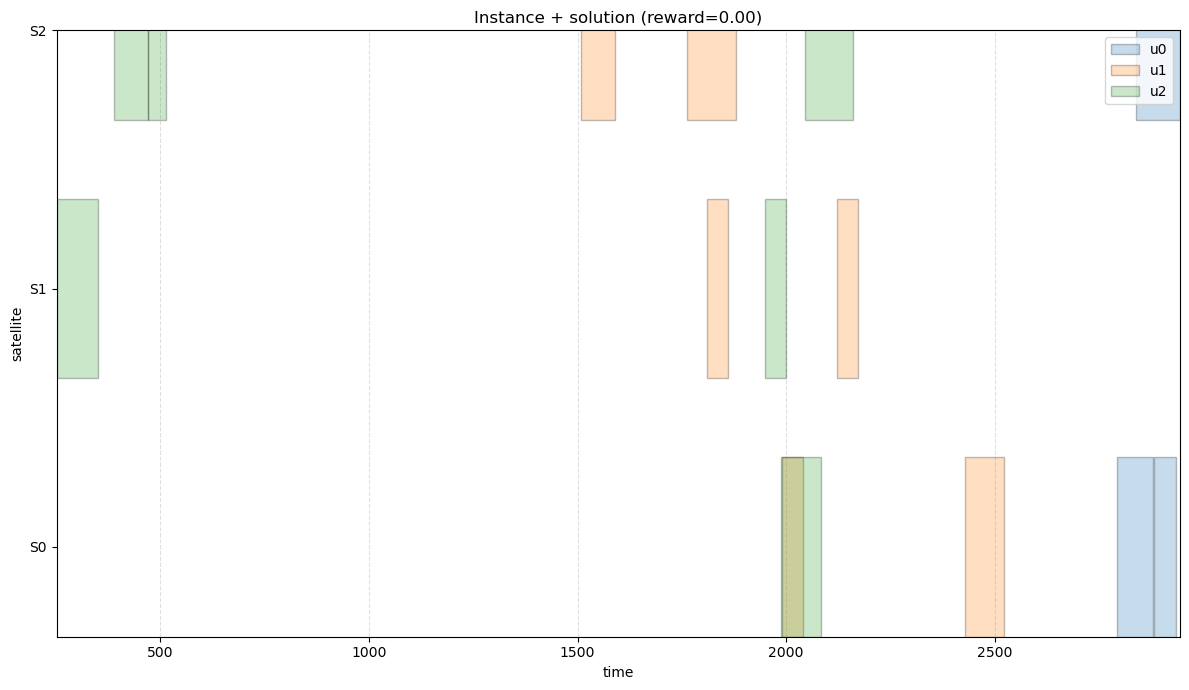

In [153]:
plot_eoscsp_windows(
    eoscsp_2,
    plan=solution,
    title=f"Instance + solution (reward={reward:.2f})",
    show_exclusives=True,
    show_labels=False,  
    show_plan_labels=True
)


In [154]:
horizon2 = 60.0

# Satellites : même horizon pour tous, capacité kappa pas importante pour le plot
satellites2 = generate_satellites(
    nb_satellites=3,
    horizon=horizon2,
    kappa_min=100,
    kappa_max=200
)

# Users : u0 non exclusif + 2 exclusifs (u1,u2)
users_no_exclusifs2 = generate_users(1)  # u0
users_exclusifs2 = generate_users_exclusifs(len(users_no_exclusifs2), satellites, 2)

users2 = users_no_exclusifs2.union(users_exclusifs2)

# Requests : 3 requêtes par user, durées visibles
requests2 = generate_requests(
    users=users2,
    nb_requests_per_user=3,
    horizon=horizon2,
    d_min=3.0,
    d_max=8.0,
    r_min=5.0,
    r_max=30.0
)

# Observations : 2 opportunités par request, fenêtres assez larges pour se chevaucher
observations2 = generate_observations(
    satellites=satellites2,
    users=users2,
    requests=requests2,
    opp_per_request=2,
    obs_window_min=10.0,
    obs_window_max=20.0
)

print(f"Generated: |S|={len(satellites2)} |U|={len(users2)} |R|={len(requests2)} |O|={len(observations2)}")


Generated: |S|=3 |U|=3 |R|=9 |O|=14


In [155]:
observations_u02 = []

for o in observations2 :
    if o.u.u_id == 0 and o.s.s_id == 0:
        observations_u02.append(o)

solution2, reward2 = planification(list(observations2),1)

print("Reward:", solution2)
for obs, t in solution2.M.items():
    print(obs.o_id, obs.t_start, obs.t_end, obs.reward)
    print(t)

Reward: <__main__.Solution object at 0x000001D262C66EA0>
2 2.204886566200375 13.354948506167414 27.024150333401813
2.204886566200375
3 9.816622695692628 28.263846607657207 27.024150333401813
9.816622695692628
11 18.69788256054695 32.9304922611977 12.970459661483584
18.69788256054695
10 15.559346808607648 31.22581452558339 12.970459661483584
22.67635605253433
5 27.804713638373695 42.99454328977054 18.125112392931158
27.804713638373695
13 36.81883368836268 46.88692935896286 29.20038721903781
36.81883368836268
9 39.093900371334136 49.14410581313596 19.710004296004062
42.86588678860485


In [156]:
def format_eoscsp(P, max_items=30) -> str:
    """
    P: instance of EOSCSP
    max_items: limit printed items per section to keep it readable
    """

    def sid(s): return getattr(s, "s_id", "?")
    def uid(u): return getattr(u, "u_id", "?")
    def rid(r): return getattr(r, "r_id", "?")
    def oid(o): return getattr(o, "o_id", "?")

    lines = []
    lines.append(f"EOSCSP instance #{P.eoscsp_id}")
    lines.append(f"|S|={len(P.S)} |U|={len(P.U)} |R|={len(P.R)} |O|={len(P.O)}")
    lines.append("")

    # --- Satellites ---
    lines.append("Satellites:")
    for i, s in enumerate(sorted(P.S, key=lambda x: getattr(x, "s_id", 0))):
        if i >= max_items:
            lines.append(f"  ... ({len(P.S)-max_items} more)")
            break
        lines.append(
            f"  S{sid(s)}: horizon=[{s.t_start:.2f},{s.t_end:.2f}] kappa={getattr(s,'kappa','?')}"
        )
    lines.append("")

    # --- Users + exclusives ---
    lines.append("Users:")
    for i, u in enumerate(sorted(P.U, key=lambda x: getattr(x, "u_id", 0))):
        if i >= max_items:
            lines.append(f"  ... ({len(P.U)-max_items} more)")
            break

        e = getattr(u, "e", set())
        lines.append(f"  u{uid(u)}: priority={getattr(u,'p','?')} exclusives={len(e)}")
        # print exclusives
        for j, (s, a, b) in enumerate(sorted(list(e), key=lambda t: (sid(t[0]), t[1]))):
            if j >= 10:
                lines.append("    ...")
                break
            lines.append(f"    - (S{sid(s)}, [{a:.2f},{b:.2f}])")
    lines.append("")

    # --- Requests ---
    lines.append("Requests:")
    for i, r in enumerate(sorted(P.R, key=lambda x: getattr(x, "r_id", 0))):
        if i >= max_items:
            lines.append(f"  ... ({len(P.R)-max_items} more)")
            break
        u = getattr(r, "u", None)
        lines.append(
            f"  r{rid(r)}: user=u{uid(u) if u else '?'} "
            f"duration={getattr(r,'duration','?')} reward={getattr(r,'reward','?')}"
        )
    lines.append("")

    # --- Observations ---
    lines.append("Observations (windows):")
    obs_sorted = sorted(P.O, key=lambda o: (getattr(o.s, "s_id", 0), o.t_start, oid(o)))
    for i, o in enumerate(obs_sorted):
        if i >= max_items:
            lines.append(f"  ... ({len(P.O)-max_items} more)")
            break
        lines.append(
            f"  o{oid(o)}: u{uid(o.u)} on S{sid(o.s)} "
            f"window=[{o.t_start:.2f},{o.t_end:.2f}] "
            f"dur={o.duration:.2f} reward={o.reward:.2f} "
            f"(r{rid(o.r)})"
        )

    return "\n".join(lines)


In [157]:
def format_solution(sol, title=None) -> str:
    """
    sol: instance of Solution with sol.M: dict[Observation, float]
    """
    def sid(s): return getattr(s, "s_id", "?")
    def uid(u): return getattr(u, "u_id", "?")
    def oid(o): return getattr(o, "o_id", "?")
    def rid(r): return getattr(r, "r_id", "?")

    lines = []
    lines.append(title if title else f"Solution #{sol.sol_id}")
    lines.append(f"Planned observations: {len(sol.M)}")
    lines.append("")

    # Compute total reward
    total_reward = sum(getattr(o, "reward", 0.0) for o in sol.M.keys())
    lines.append(f"Total reward (sum of planned observations): {total_reward:.2f}")
    lines.append("")

    # Sort by satellite then start time
    items = []
    for o, start in sol.M.items():
        end = start + getattr(o, "duration", 0.0)
        items.append((getattr(o.s, "s_id", 0), start, end, o))
    items.sort(key=lambda x: (x[0], x[1]))

    current_sid = None
    for s_id, start, end, o in items:
        if current_sid != s_id:
            current_sid = s_id
            lines.append(f"Satellite S{s_id}:")
        lines.append(
            f"  o{oid(o)} (r{rid(o.r)} u{uid(o.u)}): "
            f"start={start:.2f} end={end:.2f} "
            f"dur={o.duration:.2f} reward={o.reward:.2f}"
        )

    return "\n".join(lines)


In [158]:
# instance
P = generate_EOSCSP(2, satellites, users, requests, observations)
print(format_eoscsp(P, max_items=50))

EOSCSP instance #2
|S|=3 |U|=3 |R|=6 |O|=15

Satellites:
  S0: horizon=[0.00,3000.00] kappa=148
  S1: horizon=[0.00,3000.00] kappa=117
  S2: horizon=[0.00,3000.00] kappa=163

Users:
  u0: priority=9 exclusives=0
  u1: priority=1 exclusives=1
    - (S2, [1415.26,1624.34])
  u2: priority=10 exclusives=1
    - (S0, [1832.75,1962.92])

Requests:
  r0: user=u0 duration=7.266854936399359 reward=45.43339726482677
  r1: user=u0 duration=14.26317728819049 reward=30.876691783716698
  r2: user=u1 duration=9.813750559450414 reward=45.160271492978175
  r3: user=u1 duration=7.653980946714917 reward=12.896089329975755
  r4: user=u2 duration=6.912387662916321 reward=36.50693973232773
  r5: user=u2 duration=6.538509501030525 reward=32.117161837162854

Observations (windows):
  o9: u2 on S0 window=[1986.53,2083.11] dur=6.54 reward=32.12 (r5)
  o7: u1 on S0 window=[1988.96,2040.05] dur=9.81 reward=45.16 (r2)
  o6: u1 on S0 window=[2427.72,2523.32] dur=9.81 reward=45.16 (r2)
  o1: u0 on S0 window=[2793.45

In [159]:
print(format_solution(solution2, title="Greedy planning solution"))

Greedy planning solution
Planned observations: 7

Total reward (sum of planned observations): 147.02

Satellite S0:
  o5 (r4 u1): start=27.80 end=32.62 dur=4.82 reward=18.13
  o13 (r1 u0): start=36.82 end=42.87 dur=6.05 reward=29.20
  o9 (r6 u2): start=42.87 end=47.78 dur=4.92 reward=19.71
Satellite S1:
  o11 (r2 u0): start=18.70 end=22.68 dur=3.98 reward=12.97
Satellite S2:
  o2 (r8 u2): start=2.20 end=5.34 dur=3.14 reward=27.02
  o3 (r8 u2): start=9.82 end=12.95 dur=3.14 reward=27.02
  o10 (r2 u0): start=22.68 end=26.65 dur=3.98 reward=12.97


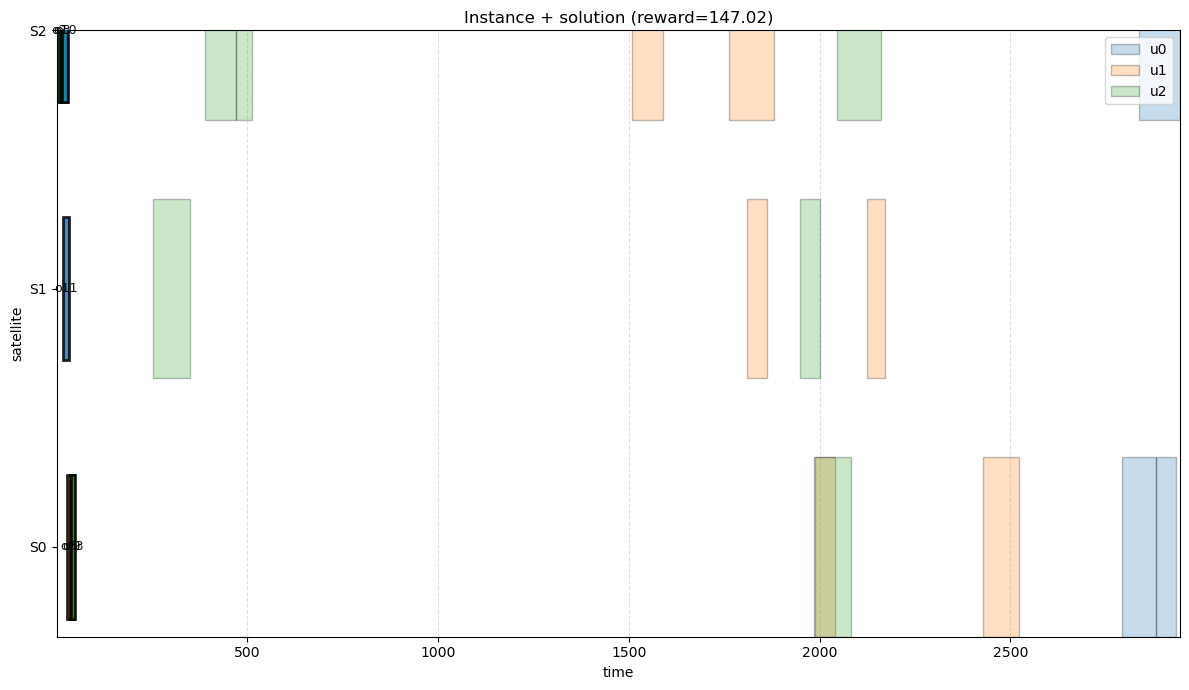

In [161]:
plot_eoscsp_windows(
    eoscsp_2,
    plan=solution2,
    title=f"Instance + solution (reward={reward2:.2f})",
    show_exclusives=True,
    show_labels=False,        # souvent mieux pour la lisibilité
    show_plan_labels=True
)

## 3 - Partie 1 : Optimisation de contraintes distribuées

## 4 - Partie 2 : Approches par enchères

## 5 - Conclusion